# Analyse statistique de l’inflation au Maroc

Projet individuel de première année à l’INSEA, filière Économie Appliquée – Statistique et Big Data.

Le fichier `data/processed/ipc_maroc_mensuel.csv` rassemble les séries mensuelles d’IPC issues des classeurs du HCP, en base 100 en 2017. L’analyse utilise uniquement ce CSV, de janvier 2017 à octobre 2026.

## 1. Importer et vérifier les données

On attend une ligne par mois et 15 séries. La vérification du calendrier est importante, car les calculs comparent chaque mois à celui qui le précède ou au même mois un an plus tôt.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

# Trouver le CSV depuis la racine du projet ou le dossier notebooks.
racine = Path.cwd()
if racine.name == "notebooks":
    racine = racine.parent
chemin = racine / "data" / "processed" / "ipc_maroc_mensuel.csv"
sorties = racine / "outputs"

donnees = pd.read_csv(chemin, encoding="utf-8-sig")

# Vérifier les dimensions, les colonnes des agrégats et les noms en double.
general = "Indice Général"
alimentation = "Alimentation"
non_alimentaire = "Produits Non Alimentaires"
agregats = [general, alimentation, non_alimentaire]
colonnes_requises = ["date"] + agregats

# Lire aussi la première ligne comme donnée, car pandas renomme les en-têtes en double.
entetes = pd.read_csv(chemin, encoding="utf-8-sig", header=None, nrows=1).iloc[0]
if entetes.isna().any() or entetes.duplicated().any():
    raise ValueError("En-têtes vides ou en double dans le CSV.")
if donnees.shape != (118, 16) or not set(colonnes_requises).issubset(donnees.columns):
    raise ValueError(f"Structure inattendue : {donnees.shape}, colonnes {donnees.columns.tolist()}.")

donnees["date"] = pd.to_datetime(donnees["date"], format="%Y-%m-%d", errors="raise")
if donnees["date"].isna().any() or donnees["date"].duplicated().any():
    raise ValueError("Dates manquantes ou en double.")

ipc = donnees.set_index("date").sort_index()
mois_attendus = pd.date_range("2017-01-01", "2026-10-01", freq="MS")
if not ipc.index.equals(mois_attendus):
    raise ValueError("Le calendrier contient des mois absents ou des dates inattendues.")

ipc = ipc.apply(pd.to_numeric, errors="raise")
# Arrêter l’analyse si un indice manque et indiquer les séries concernées.
manquantes = ipc.isna().sum()
series_incompletes = manquantes[manquantes > 0]
if not series_incompletes.empty:
    raise ValueError(
        f"Valeurs manquantes dans le CSV ({manquantes.sum()} au total) : "
        f"{series_incompletes.to_dict()}"
    )
if (ipc.le(0) | ipc.eq(float("inf"))).any().any():
    raise ValueError("Les indices doivent être strictement positifs et finis.")

# Les trois agrégats et les douze divisions sont analysés séparément.
divisions = ipc.columns.drop(agregats).tolist()
print(f"{ipc.shape[0]} mois, {ipc.shape[1]} séries d’IPC, {len(divisions)} divisions.")
print("Contrôle réussi : aucun indice manquant.")
display(ipc.head())

118 mois, 15 séries d’IPC, 12 divisions.
Contrôle réussi : aucun indice manquant.


,Alimentation,Produits Non Alimentaires,Indice Général,Produits alimentaires et boissons non alcoolisées,"Boissons alcoolisées, tabac et stupéfiants",Articles d'habillement et chaussures,"Logement, eau, gaz, électricité et autres combustibles","Meubles, articles de ménage et entretien courant du foyer",Santé,Transports,Communications,Loisirs et culture,Enseignement,Restaurants et hôtels,Biens et services divers
date,,,,,,,,,,,,,,,
2017-01-01,98.6,99.9,99.4,98.6,100.0,99.8,99.9,100.0,99.7,100.2,100.1,99.8,99.7,99.7,99.9
2017-02-01,98.8,100.0,99.5,98.8,100.0,99.8,99.9,100.0,99.7,100.3,100.1,100.0,99.8,99.9,100.1
2017-03-01,98.2,100.0,99.3,98.1,100.0,99.8,99.9,100.0,99.9,100.4,100.1,100.0,99.8,99.9,100.1
2017-04-01,98.5,99.9,99.3,98.4,100.0,99.8,99.9,99.9,100.1,99.8,100.0,100.2,99.4,99.8,100.0
2017-05-01,99.6,99.8,99.7,99.5,100.0,99.6,99.9,99.9,100.1,99.6,100.0,100.1,99.5,99.8,99.9


## 2. Calculer les taux d’inflation

Soit $I_t$ le niveau de l’IPC au mois $t$. L’IPC s’exprime en points d’indice. Les taux ci-dessous s’expriment en pourcentage.

- **Inflation mensuelle** : $\displaystyle \pi^{(1)}_t = 100\left(\frac{I_t}{I_{t-1}} - 1\right)$.
- **Inflation en glissement annuel** : $\displaystyle \pi^{(12)}_t = 100\left(\frac{I_t}{I_{t-12}} - 1\right)$.

Le glissement annuel compare deux mois séparés de douze mois. Un taux moyen sur une année civile comparerait les niveaux moyens de deux années. Les premières dates pour lesquelles l’indice de comparaison est absent restent sans taux.

In [2]:
# Le calendrier a été vérifié avant de décaler les indices.
taux_mensuel = 100 * (ipc / ipc.shift(1) - 1)
taux_annuel = 100 * (ipc / ipc.shift(12) - 1)

inflation_generale = pd.DataFrame({
    "IPC général": ipc[general],
    "Inflation mensuelle (%)": taux_mensuel[general],
    "Glissement annuel (%)": taux_annuel[general],
})
display(inflation_generale.head(13).round(2))

,IPC général,Inflation mensuelle (%),Glissement annuel (%)
date,,,
2017-01-01,99.4,NaN,NaN
2017-02-01,99.5,0.1,NaN
2017-03-01,99.3,-0.2,NaN
2017-04-01,99.3,0.0,NaN
2017-05-01,99.7,0.4,NaN
2017-06-01,100.0,0.3,NaN
2017-07-01,99.5,-0.5,NaN
2017-08-01,99.8,0.3,NaN
2017-09-01,100.6,0.8,NaN


## 3. Résumer les séries

La moyenne vaut $\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$. La médiane partage les observations ordonnées en deux moitiés. Le minimum et le maximum donnent les bornes observées.

On utilise la variance corrigée $\displaystyle s^2 = \frac{\sum_{i=1}^n (x_i-\bar{x})^2}{n-1}$ et l’écart-type $s = \sqrt{s^2}$. Ils mesurent la dispersion des observations sur la période. L’écart-type d’un taux s’exprime en points de pourcentage et sa variance en points de pourcentage au carré. Les calculs ignorent les cellules manquantes et indiquent le nombre d’observations utilisées.

In [3]:
def statistiques(tableau):
    """Résumer chaque colonne avec les observations disponibles."""
    resume = tableau.agg(["count", "mean", "median", "min", "max", "var", "std"]).T
    resume.columns = [
        "Observations", "Moyenne", "Médiane", "Minimum", "Maximum", "Variance", "Écart-type"
    ]
    return resume.round(2)


for titre, tableau in [
    ("Niveaux d’IPC (points d’indice)", ipc),
    ("Inflation mensuelle (%)", taux_mensuel),
    ("Inflation en glissement annuel (%)", taux_annuel),
]:
    display(Markdown(f"**{titre}**"))
    display(statistiques(tableau))

**Niveaux d’IPC (points d’indice)**

,Observations,Moyenne,Médiane,Minimum,Maximum,Variance,Écart-type
Alimentation,118.0,113.94,105.05,98.2,132.8,177.99,13.34
Produits Non Alimentaires,118.0,106.60,105.65,99.7,116.0,25.07,5.01
Indice Général,118.0,109.49,105.45,99.3,121.8,67.21,8.20
Produits alimentaires et boissons non alcoolisées,118.0,113.40,104.25,98.1,132.4,178.22,13.35
"Boissons alcoolisées, tabac et stupéfiants",118.0,127.29,125.50,99.9,150.6,224.88,15.00
Articles d'habillement et chaussures,118.0,108.40,106.50,99.6,118.2,46.18,6.80
"Logement, eau, gaz, électricité et autres combustibles",118.0,104.03,102.95,99.9,111.1,12.49,3.53
"Meubles, articles de ménage et entretien courant du foyer",118.0,105.94,103.25,99.9,114.6,31.97,5.65
Santé,118.0,101.27,101.50,99.7,102.7,0.56,0.75
Transports,118.0,110.82,109.55,95.9,129.3,85.12,9.23


**Inflation mensuelle (%)**

,Observations,Moyenne,Médiane,Minimum,Maximum,Variance,Écart-type
Alimentation,117.0,0.25,0.20,-2.44,3.92,1.53,1.24
Produits Non Alimentaires,117.0,0.13,0.10,-0.68,1.23,0.07,0.27
Indice Général,117.0,0.18,0.19,-1.00,1.79,0.31,0.56
Produits alimentaires et boissons non alcoolisées,117.0,0.24,0.20,-2.50,4.09,1.69,1.30
"Boissons alcoolisées, tabac et stupéfiants",117.0,0.36,0.00,-0.10,10.89,2.13,1.46
Articles d'habillement et chaussures,117.0,0.14,0.10,-0.70,1.58,0.09,0.30
"Logement, eau, gaz, électricité et autres combustibles",117.0,0.09,0.09,-0.10,1.61,0.05,0.22
"Meubles, articles de ménage et entretien courant du foyer",117.0,0.12,0.09,-0.20,1.72,0.05,0.22
Santé,117.0,0.02,0.00,-1.75,0.59,0.04,0.19
Transports,117.0,0.23,0.10,-4.29,6.50,1.87,1.37


**Inflation en glissement annuel (%)**

,Observations,Moyenne,Médiane,Minimum,Maximum,Variance,Écart-type
Alimentation,106.0,3.07,0.89,-3.87,20.08,29.06,5.39
Produits Non Alimentaires,106.0,1.51,1.14,-0.39,4.98,1.41,1.19
Indice Général,106.0,2.12,1.19,-0.75,10.08,6.90,2.63
Produits alimentaires et boissons non alcoolisées,106.0,3.01,0.74,-4.19,20.84,31.86,5.64
"Boissons alcoolisées, tabac et stupéfiants",106.0,4.68,3.66,-0.08,10.89,9.18,3.03
Articles d'habillement et chaussures,106.0,1.88,1.53,-0.58,5.84,2.33,1.53
"Logement, eau, gaz, électricité et autres combustibles",106.0,1.12,0.79,0.30,3.82,0.86,0.93
"Meubles, articles de ménage et entretien courant du foyer",106.0,1.48,0.63,-0.10,6.73,3.44,1.86
Santé,106.0,0.18,0.20,-1.46,1.39,0.35,0.59
Transports,106.0,2.35,0.83,-7.25,18.28,28.76,5.36


## 4. Tableau annuel de l’IPC général

Pour une année civile complète $a$, on calcule d’abord la moyenne des douze indices mensuels, $\displaystyle \bar I_a = \frac{1}{12}\sum_{m=1}^{12} I_{a,m}$. Le taux d’inflation moyen annuel compare ensuite les niveaux moyens de deux années complètes consécutives :

$$
\pi_a = 100\left(\frac{\bar I_a}{\bar I_{a-1}} - 1\right).
$$

Le glissement annuel de décembre compare deux mois de décembre. Le taux moyen annuel utilise les douze mois de chacune des deux années. Il se calcule à partir des indices moyens, et non en faisant la moyenne des glissements mensuels sur douze mois.

Pour 2017, le CSV ne fournit aucune donnée pour 2016. Pour 2026, seuls les mois de janvier à octobre sont disponibles. Les taux moyens annuels de ces deux années restent donc vides. Une comparaison à période identique est calculée séparément pour janvier à octobre 2026 et janvier à octobre 2025.

In [4]:
indice_general = ipc[general]

# Calculer l’IPC moyen observé et compter les mois disponibles par année.
bilan_annuel = indice_general.groupby(indice_general.index.year).agg(["count", "mean"])
bilan_annuel.index.name = "Année"
bilan_annuel.columns = ["Mois disponibles", "IPC moyen sur les mois disponibles"]

# Seules les années complètes entrent dans le calcul du taux moyen annuel.
ipc_annee_complete = bilan_annuel["IPC moyen sur les mois disponibles"].where(
    bilan_annuel["Mois disponibles"] == 12
)
bilan_annuel["Inflation moyenne annuelle (%)"] = 100 * (
    ipc_annee_complete / ipc_annee_complete.shift(1) - 1
)
display(bilan_annuel.style.format({
    "IPC moyen sur les mois disponibles": "{:.2f}",
    "Inflation moyenne annuelle (%)": "{:.2f}",
}, na_rep="—", decimal=","))

# Comparer les mêmes dix mois, sans extrapoler novembre et décembre 2026.
moyenne_2025 = indice_general.loc["2025-01":"2025-10"].mean()
moyenne_2026 = indice_general.loc["2026-01":"2026-10"].mean()
variation_janvier_octobre = 100 * (moyenne_2026 / moyenne_2025 - 1)
taux_partiel = f"{variation_janvier_octobre:.2f}".replace(".", ",")
display(Markdown(
    "De janvier à octobre 2026, l’IPC général moyen varie de "
    f"**{taux_partiel} %** par rapport à janvier à octobre 2025."
))

,Mois disponibles,IPC moyen sur les mois disponibles,Inflation moyenne annuelle (%)
Année,,,
2017,12,"99,98",—
2018,12,"101,58","1,60"
2019,12,"101,83","0,25"
2020,12,"102,47","0,62"
2021,12,"103,90","1,40"
2022,12,"110,82","6,66"
2023,12,"117,57","6,09"
2024,12,"118,73","0,99"
2025,12,"119,56","0,70"


De janvier à octobre 2026, l’IPC général moyen varie de **0,43 %** par rapport à janvier à octobre 2025.

## 5. Visualiser l’IPC général et ses taux

Les axes distinguent le niveau de l’indice et les taux. Un glissement annuel positif qui diminue indique que les prix restent supérieurs à ceux du même mois de l’année précédente, avec un écart plus faible.

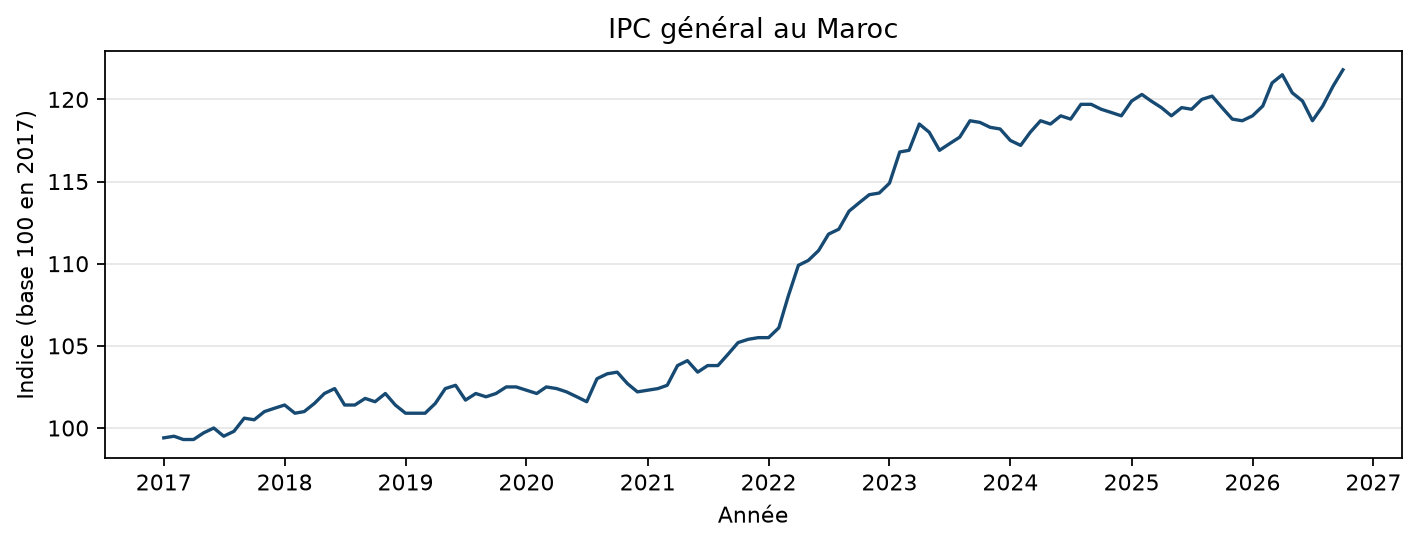

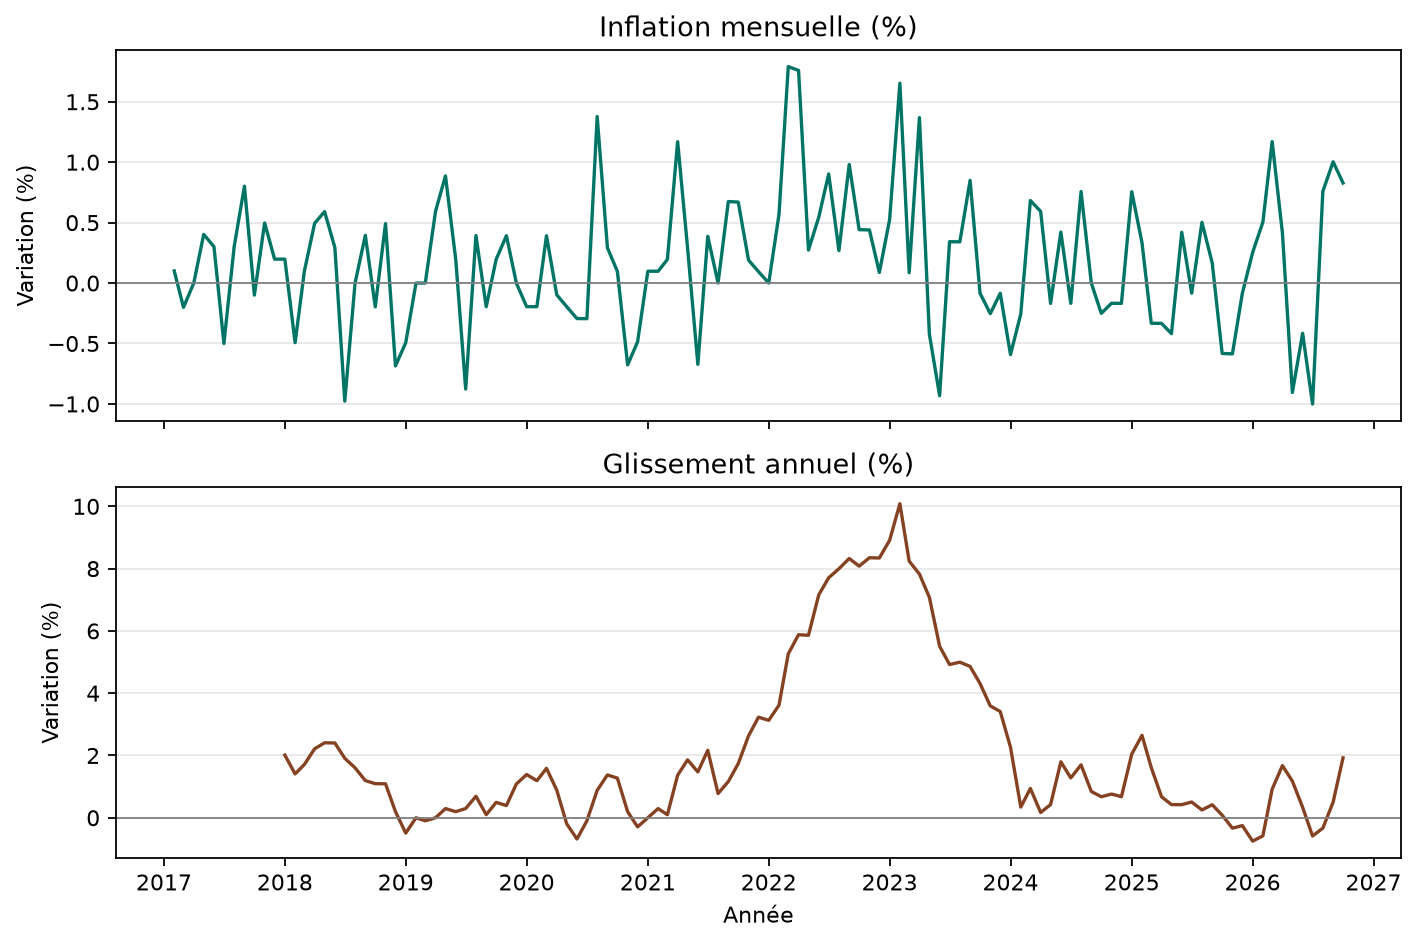

In [5]:
sorties.mkdir(exist_ok=True)


def enregistrer_graphique(figure, nom):
    """Enregistrer le graphique et l’afficher dans le notebook."""
    chemin_png = sorties / nom
    figure.tight_layout()
    figure.savefig(chemin_png, dpi=160, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(chemin_png)))


figure, axe = plt.subplots(figsize=(9, 3.5))
axe.plot(ipc.index, ipc[general], color="#174A73")
axe.set(title="IPC général au Maroc", xlabel="Année", ylabel="Indice (base 100 en 2017)")
axe.grid(axis="y", alpha=0.3)
enregistrer_graphique(figure, "02_ipc_general.png")

figure, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for axe, colonne, couleur in zip(axes, inflation_generale.columns[1:], ["#007566", "#854222"]):
    axe.plot(inflation_generale.index, inflation_generale[colonne], color=couleur)
    axe.axhline(0, color="gray", linewidth=0.8)
    axe.set(title=colonne, ylabel="Variation (%)")
    axe.grid(axis="y", alpha=0.3)
axes[-1].set_xlabel("Année")
enregistrer_graphique(figure, "02_inflation_generale.png")

## 6. Comparer l’alimentation et les produits non alimentaires

Les niveaux montrent comment chaque indice a évolué par rapport à sa propre base. Les glissements annuels comparent le rythme de hausse ou de baisse. Une différence de taux entre les deux agrégats s’exprime en points de pourcentage.

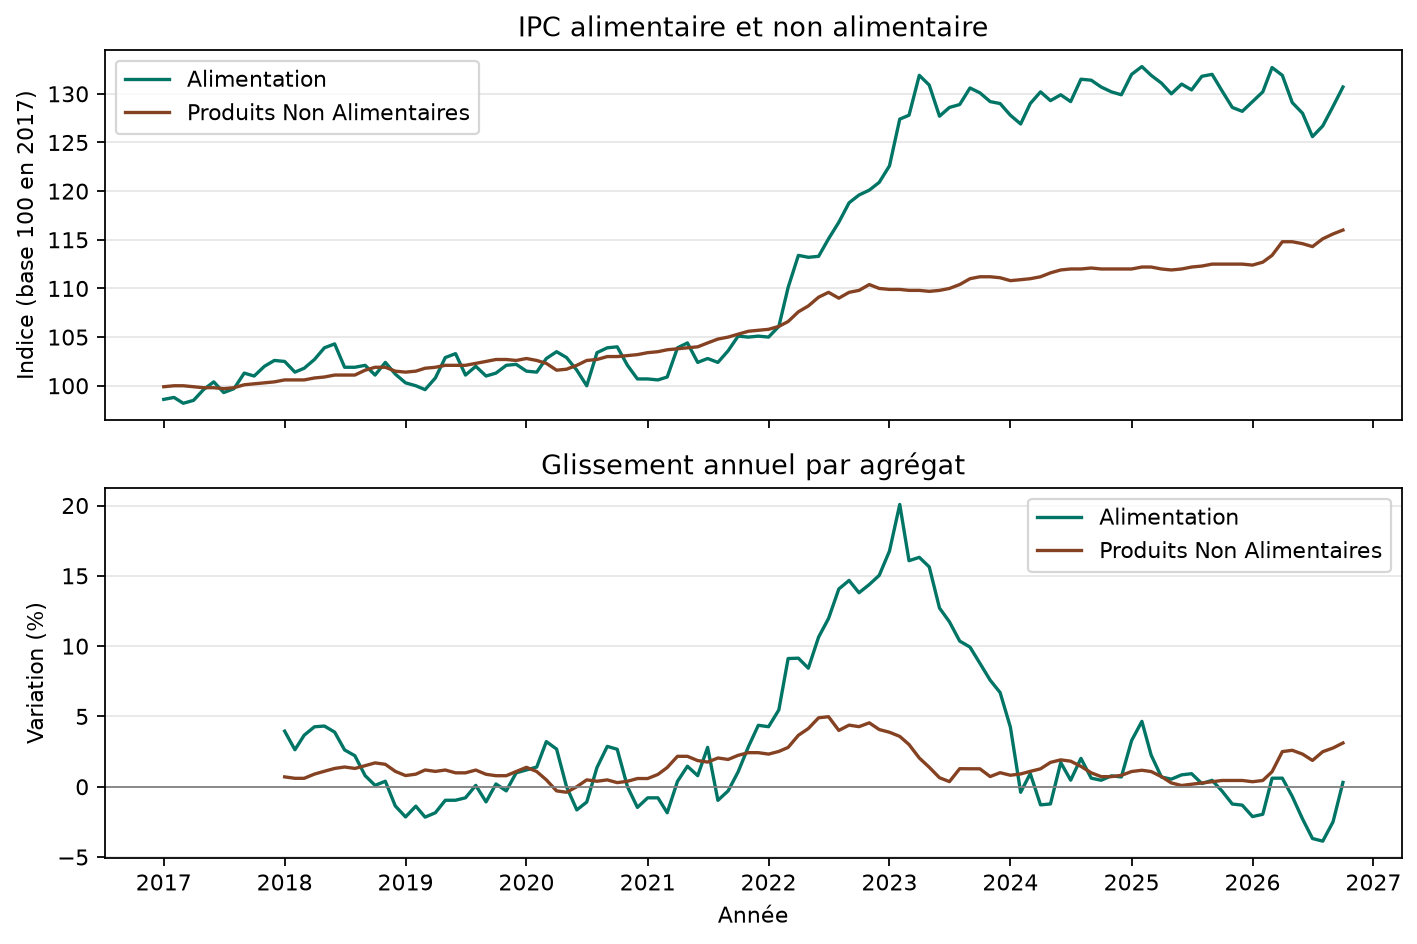

In [6]:
groupes = [alimentation, non_alimentaire]
figure, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for groupe, couleur in zip(groupes, ["#007566", "#854222"]):
    axes[0].plot(ipc.index, ipc[groupe], label=groupe, color=couleur)
    axes[1].plot(taux_annuel.index, taux_annuel[groupe], label=groupe, color=couleur)

axes[0].set(title="IPC alimentaire et non alimentaire", ylabel="Indice (base 100 en 2017)")
axes[1].set(title="Glissement annuel par agrégat", ylabel="Variation (%)", xlabel="Année")
axes[1].axhline(0, color="gray", linewidth=0.8)
for axe in axes:
    axe.legend()
    axe.grid(axis="y", alpha=0.3)
enregistrer_graphique(figure, "02_alimentation_non_alimentaire.png")

## 7. Comparer les douze divisions de consommation

La comparaison utilise la moyenne des glissements annuels disponibles de janvier 2018 à octobre 2026. Cette moyenne résume le rythme sur les mois observés. La contribution d’une division à l’inflation générale dépend aussi de son poids dans le panier, information absente du CSV. La division « Produits alimentaires et boissons non alcoolisées » est distincte de l’agrégat « Alimentation » utilisé ci-dessus.

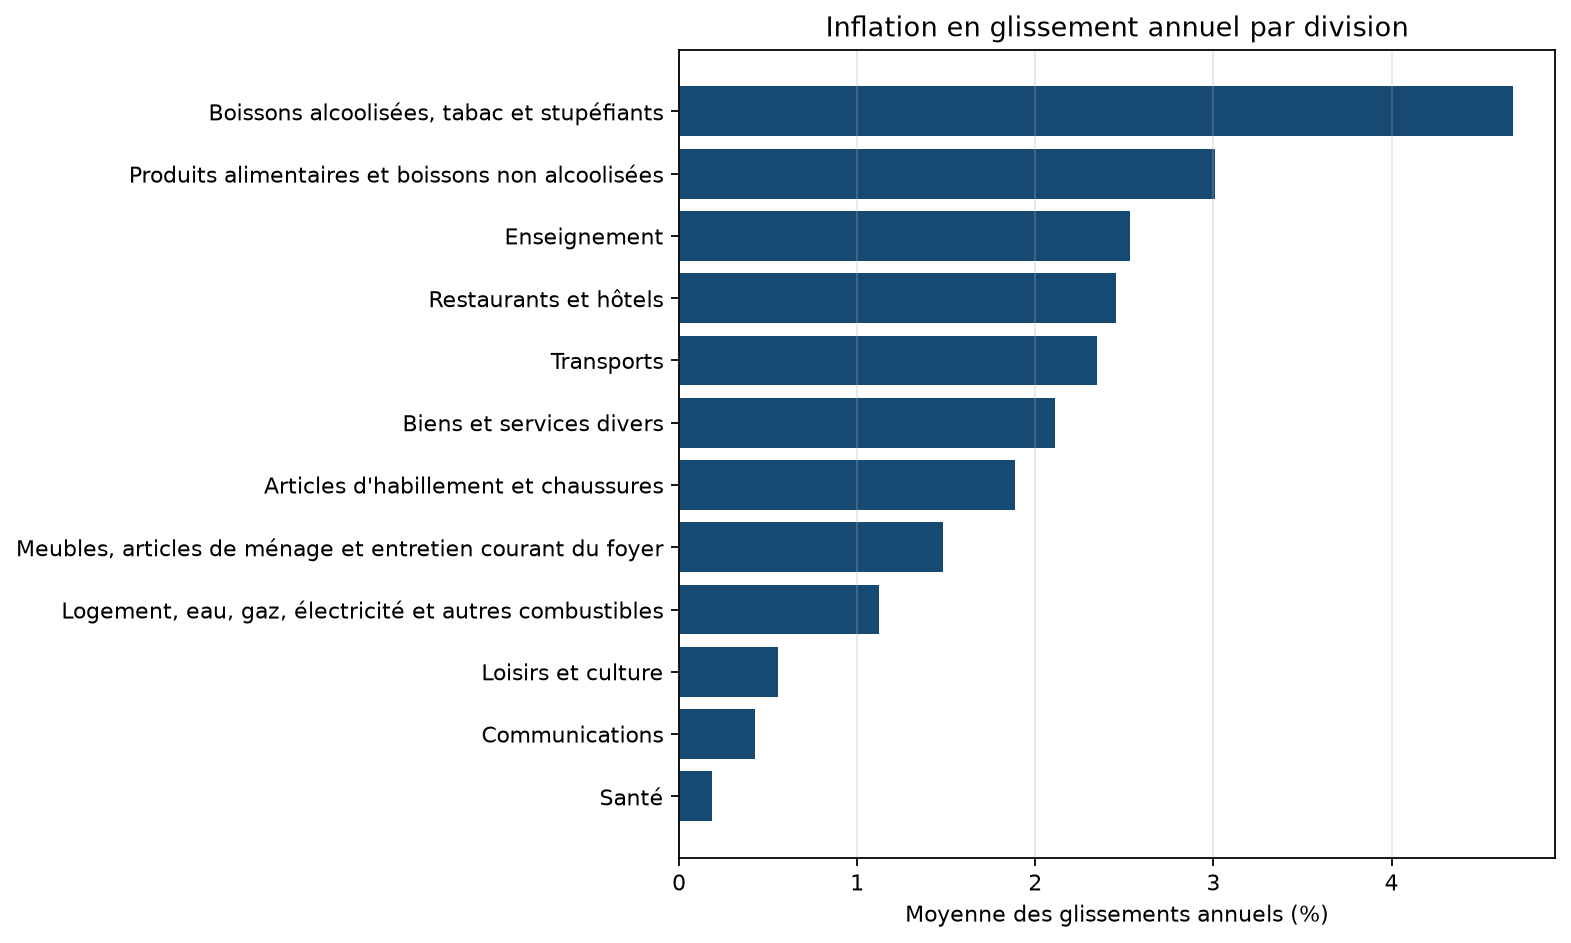

In [7]:
moyennes_divisions = taux_annuel[divisions].mean().sort_values()
figure, axe = plt.subplots(figsize=(10, 6))
axe.barh(moyennes_divisions.index, moyennes_divisions, color="#174A73")
axe.axvline(0, color="gray", linewidth=0.8)
axe.set(
    title="Inflation en glissement annuel par division",
    xlabel="Moyenne des glissements annuels (%)",
)
axe.grid(axis="x", alpha=0.3)
enregistrer_graphique(figure, "02_inflation_divisions.png")

## 8. Repérer les fortes hausses

On retient les cinq mois de plus forte hausse de l’IPC général pour chaque horizon. Le classement utilise les taux avant arrondi. Des mois consécutifs en tête du classement annuel signalent une période où l’écart avec les prix d’un an plus tôt est resté élevé.

In [8]:
colonne_mensuelle = "Inflation mensuelle (%)"
colonne_annuelle = "Glissement annuel (%)"
pics_mensuels = inflation_generale[colonne_mensuelle].nlargest(5)
pics_annuels = inflation_generale[colonne_annuelle].nlargest(5)

for pics in [pics_mensuels, pics_annuels]:
    display(Markdown(f"**{pics.name}**"))
    classement = pics.rename_axis("Mois").to_frame()
    classement.index = classement.index.strftime("%Y-%m")
    display(classement.round(2))

**Inflation mensuelle (%)**

,Inflation mensuelle (%)
Mois,
2022-03,1.79
2022-04,1.76
2023-02,1.65
2020-08,1.38
2023-04,1.37


**Glissement annuel (%)**

,Glissement annuel (%)
Mois,
2023-02,10.08
2023-01,8.91
2022-11,8.35
2022-12,8.34
2022-09,8.33


## 9. Interprétations économiques

Les chiffres du commentaire ci-dessous sont calculés à partir du CSV lorsque la cellule est exécutée. Les deux horizons sont commentés séparément.

In [9]:
def nombre_fr(valeur):
    """Afficher un nombre avec deux décimales et une virgule."""
    return f"{valeur:.2f}".replace(".", ",")


date_pic_mensuel = pics_mensuels.index[0]
date_pic_annuel = pics_annuels.index[0]
taux_pic_mensuel = nombre_fr(pics_mensuels.iloc[0])
taux_pic_annuel = nombre_fr(pics_annuels.iloc[0])
taux_alimentation = taux_annuel.loc[date_pic_annuel, alimentation]
taux_non_alimentaire = taux_annuel.loc[date_pic_annuel, non_alimentaire]
ecart = nombre_fr(taux_alimentation - taux_non_alimentaire)
niveau_debut = nombre_fr(ipc[general].iloc[0])
niveau_fin = nombre_fr(ipc[general].iloc[-1])

display(Markdown(f"""
- **Évolution générale.** L’IPC général passe de **{niveau_debut}** en janvier 2017 à **{niveau_fin}** en octobre 2026. Ces chiffres sont des niveaux d’indice. La plus forte hausse d’un mois au suivant est de **{taux_pic_mensuel} %** en **{date_pic_mensuel:%Y-%m}**. Le glissement annuel culmine à **{taux_pic_annuel} %** en **{date_pic_annuel:%Y-%m}**.
- **Alimentation.** Au mois du pic annuel de l’IPC général, les glissements annuels atteignent **{nombre_fr(taux_alimentation)} %** pour l’alimentation et **{nombre_fr(taux_non_alimentaire)} %** pour les produits non alimentaires. L’écart alimentation moins non-alimentaire s’élève à **{ecart} points de pourcentage**. Un ménage dont le budget est davantage consacré à l’alimentation peut être plus exposé à cette hausse, à composition du panier donnée.
- **Divisions.** La moyenne des glissements annuels est la plus élevée pour **{moyennes_divisions.idxmax()}** (**{nombre_fr(moyennes_divisions.max())} %**) et la plus faible pour **{moyennes_divisions.idxmin()}** (**{nombre_fr(moyennes_divisions.min())} %**). Cet écart montre que les prix ont évolué à des rythmes différents selon les postes.
"""))


- **Évolution générale.** L’IPC général passe de **99,40** en janvier 2017 à **121,80** en octobre 2026. Ces chiffres sont des niveaux d’indice. La plus forte hausse d’un mois au suivant est de **1,79 %** en **2022-03**. Le glissement annuel culmine à **10,08 %** en **2023-02**.
- **Alimentation.** Au mois du pic annuel de l’IPC général, les glissements annuels atteignent **20,08 %** pour l’alimentation et **3,58 %** pour les produits non alimentaires. L’écart alimentation moins non-alimentaire s’élève à **16,49 points de pourcentage**. Un ménage dont le budget est davantage consacré à l’alimentation peut être plus exposé à cette hausse, à composition du panier donnée.
- **Divisions.** La moyenne des glissements annuels est la plus élevée pour **Boissons alcoolisées, tabac et stupéfiants** (**4,68 %**) et la plus faible pour **Santé** (**0,18 %**). Cet écart montre que les prix ont évolué à des rythmes différents selon les postes.


## 10. Sources et limites

**Source.** Haut-Commissariat au Plan (HCP), indice des prix à la consommation du Maroc, base 100 en 2017. Le CSV `data/processed/ipc_maroc_mensuel.csv` rassemble trois classeurs mensuels du HCP : grandes divisions, divisions du groupe 1 et divisions du groupe 2. Le script `src/clean_ipc.py` documente leur fusion. [Indicateurs IPC du HCP](https://www.hcp.ma/Indicateurs-Indices-des-prix-a-la-consommation-IPC_r351.html)

- **Revenus et pouvoir d’achat.** L’IPC mesure l’évolution des prix d’un panier de référence. À revenu nominal constant, un panier plus cher réduit ce que ce revenu permet d’acheter. Pour mesurer l’évolution effective du pouvoir d’achat des ménages, il faut aussi des données de revenu comparables dans le temps. Les ménages peuvent être exposés différemment selon la composition de leur panier.
- **Quantités consommées.** Une hausse de l’indice d’un poste renseigne sur ses prix. Les quantités effectivement achetées nécessitent des données de consommation.
- **Substitutions entre produits.** Des écarts de hausse entre postes peuvent modifier les prix relatifs. Observer une substitution demande des données sur les achats par produit. Attribuer ce changement aux prix exige aussi de tenir compte d’autres facteurs, comme les revenus.